In [32]:
import numpy as np
from gnuradio.filter import firdes
from matplotlib import pyplot as plt
from scipy.signal import firwin, freqz, lfilter

In [33]:
FS_IN = 2.4e6
D = 16
FS = FS_IN / D
NTAPS = 129
FC_REC = 75e3

In [34]:
numtaps = max(64, 8 * D)
if numtaps % 2 == 0:
    numtaps += 1

taps = firwin(
    numtaps,
    cutoff=1.0 / D,
    window="hamming",
)

10.0 kHz: 0.023371879258032007 dB
20.0 kHz: 0.04056081369004591 dB
30.0 kHz: 0.02724982059839362 dB
40.0 kHz: 0.026552569217596193 dB
54.0 kHz: -0.4444985143305999 dB
60.0 kHz: -1.2047815131298285 dB
64.0 kHz: -2.0236886474148505 dB
72.0 kHz: -4.634349133089356 dB
75.0 kHz: -6.0142015423371085 dB


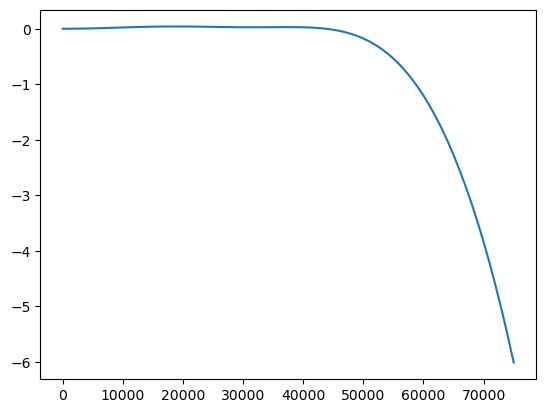

In [35]:
w, h = freqz(taps, 1, worN=1 << 16, fs=FS_IN)
mag_db = 20 * np.log10(np.abs(h) / np.abs(h[0]))

for f in [10e3, 20e3, 30e3, 40e3, 54e3, 60e3, 64e3, 72e3, 75e3]:
    print(f / 1e3, "kHz:", np.interp(f, w, mag_db), "dB")

freqs = [x * 1e3 for x in range(0, 75 + 1)]
values = [np.interp(f, w, mag_db) for f in freqs]
plt.plot(freqs, values)
plt.show()

In [36]:
hs = np.array(firdes.low_pass(1, FS, 58e3, 8e3))
hn = np.array(firdes.band_pass(1, FS, 64e3, 72e3, 4e3))

In [37]:
N = 1 << 15
f = np.fft.fftfreq(N, 1 / FS)

In [38]:
psd = np.zeros(N)
for m in range(-D // 2, D // 2):
    _, H = freqz(taps, 1, worN=2 * np.pi * (f + m * FS) / FS_IN)
    psd += np.abs(H) ** 2
psd /= psd[np.argmin(np.abs(f))]

In [39]:
Hs = np.abs(np.fft.fft(hs, N)) ** 2
Hn = np.abs(np.fft.fft(hn, N)) ** 2

In [40]:
k_exact = np.sum(psd * Hs) / np.sum(psd * Hn)
k_white = np.sum(hs**2) / np.sum(hn**2)
print("k (perfectly flat passband):", k_white, 10 * np.log10(k_white), "dB")
print("k (exact)  :", k_exact, 10 * np.log10(k_exact), "dB")

k (perfectly flat passband): 8.518937766792561 9.30385445614048 dB
k (exact)  : 14.508427687332603 11.616203494663505 dB


In [41]:
rng = np.random.default_rng(0)
n = rng.standard_normal(2_400_000 * 10) + 1j * rng.standard_normal(2_400_000 * 10)
y = lfilter(taps, 1, n)[::D]
ps = np.mean(np.abs(lfilter(hs, 1, y)) ** 2)
pn = np.mean(np.abs(lfilter(hn, 1, y)) ** 2)
print("k (simul):", ps / pn, 10 * np.log10(ps / pn), "dB")

k (simul): 14.493587102053327 11.611758848383339 dB
